# 多因子选股量化策略 · 端到端作品集（Capstone）

> 一条完整、可复现的量化研究链路：
> **数据 → 因子 → 因子评估 → 标签 → 模型（滚动 walk-forward）→ 组合 → 回测（含成本）→ 模拟盘衔接**。
> 数据：沪深 300 成分股（300 只）日频后复权数据，自动读到本地最新交易日。

## 0. 环境与随机种子

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np
import pandas as pd
import qlib
from l2.config import SEED, load_universe
import config
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
from qlib.data import D
codes = load_universe('hs300')
print('股票池数量=%d 随机种子=%d' % (len(codes), SEED))

[23284:MainThread](2026-11-05 16:54:49,094) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[23284:MainThread](2026-11-05 16:54:51,086) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[23284:MainThread](2026-11-05 16:54:51,088) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


股票池数量=300 随机种子=42


## 1. 数据加载（后复权价、成交量、市值）

In [2]:
def load_wide(field):
    panel = D.features(codes, [field], start_time='2018-01-01', freq='day')
    return panel[field].unstack('instrument')
close = load_wide('$close')
volume = load_wide('$volume')
mktcap = load_wide('$mkt_cap_ard')
ret = close.pct_change(fill_method=None)
print('价格表形状=%s 日期范围 %s ~ %s' % (close.shape, close.index[0].date(), close.index[-1].date()))

价格表形状=(2141, 300) 日期范围 2018-01-02 ~ 2026-11-02


## 2. 因子构建

四个有代表性的截面因子：5 日反转、20 日波动、市值（log）、60 日动量。

In [3]:
factors = {
    'REV5': close.pct_change(5, fill_method=None),
    'VOL20': ret.rolling(20).std(),
    'SIZE': np.log(mktcap),
    'MOM60': close.pct_change(60, fill_method=None),
}
for k, v in factors.items():
    print(k, 'NaN比例=%.3f' % v.isna().mean().mean())

REV5 NaN比例=0.118
VOL20 NaN比例=0.125
SIZE NaN比例=0.115
MOM60 NaN比例=0.143


## 3. 因子评估：截面 RankIC / IR / 胜率

In [4]:
def rank_ic(factor, fwd_ret):
    aligned = factor.rank(axis=1)
    tgt = fwd_ret.rank(axis=1)
    ics = aligned.corrwith(tgt, axis=1)
    return ics.dropna()
fwd1 = ret.shift(-1)
summary = {}
for name, fac in factors.items():
    ics = rank_ic(fac, fwd1)
    summary[name] = {'IC均值': ics.mean(), 'IR': ics.mean()/ics.std(),
                     '胜率': (ics > 0).mean()}
ic_df = pd.DataFrame(summary).T.round(4)
print(ic_df)

         IC均值      IR      胜率
REV5  -0.0232 -0.1140  0.4543
VOL20 -0.0226 -0.0852  0.4627
SIZE  -0.0015 -0.0082  0.4911
MOM60 -0.0062 -0.0268  0.4899


## 4. 标签与模型特征

标签：未来 5 日收益的**截面 rank**（前面研究验证 rank 标签比原始收益更稳健）。
特征：四个因子截面标准化后的值。

In [5]:
fwd5 = ret.shift(-5)
label = fwd5.rank(axis=1)
def cross_scale(df):
    return df.sub(df.mean(axis=1), axis=0).div(df.std(axis=1), axis=0)
X = pd.concat([cross_scale(v).stack() for v in factors.values()], axis=1)
X.columns = list(factors.keys())
y = label.stack()
common = X.index.intersection(y.index)
X, y = X.loc[common], y.loc[common]
print('特征矩阵=%s 标签=%s' % (X.shape, y.shape))

特征矩阵=(566711, 4) 标签=(566711,)


## 5. LightGBM 滚动 walk-forward 预测

按年度滚动：用过去所有数据训练，预测下一年，避免未来函数。

In [6]:
import lightgbm as lgb
years = sorted(set(pd.DatetimeIndex(X.index.get_level_values(0)).year))
test_years = years[2:]
preds = []
for ty in test_years:
    dates = pd.DatetimeIndex(X.index.get_level_values(0))
    tr = dates.year < ty
    te = dates.year == ty
    model = lgb.LGBMRegressor(n_estimators=200, max_depth=4, learning_rate=0.05,
                              subsample=0.8, verbose=-1, random_state=SEED)
    model.fit(X[tr], y[tr])
    p = pd.Series(model.predict(X[te]), index=X.index[te])
    preds.append(p)
pred = pd.concat(preds).sort_index()
print('样本外预测条数=%d 年份=%s' % (len(pred), test_years))

样本外预测条数=456730 年份=[2020, 2021, 2022, 2023, 2024, 2025, 2026]


## 6. 模型评估：样本外 RankIC

In [7]:
pred_wide = pred.unstack('instrument')
oos_ics = pred_wide.rank(axis=1).corrwith(fwd5.rank(axis=1), axis=1).dropna()
print('样本外 RankIC 均值=%.4f IR=%.4f 胜率=%.3f'
      % (oos_ics.mean(), oos_ics.mean()/oos_ics.std(), (oos_ics > 0).mean()))

样本外 RankIC 均值=0.0143 IR=0.0930 胜率=0.536


## 7. 组合构建：每月按预测分取 Top30 等权

月末调仓，选预测分最高的 30 只等权（单票约 3.3%，自然满足集中度约束）。

In [8]:
month_end = pd.Series(pred_wide.index, index=pred_wide.index).resample('ME').last().dropna()
target = pd.DataFrame(np.nan, index=close.index, columns=close.columns, dtype=float)
for d in month_end:
    if d not in pred_wide.index: continue
    row = pred_wide.loc[d].dropna()
    top = row.nlargest(30).index
    target.loc[d, :] = 0.0          # 先整行清零，落选股票旧权重归零，防止杠杆累积
    target.loc[d, top] = 1/len(top)
weights = target.ffill().fillna(0)
print('调仓次数=%d 权重行和最大=%.3f 平均持仓数=%.1f'
      % (len(month_end), weights.sum(axis=1).max(), (weights != 0).sum(axis=1).mean()))

调仓次数=82 权重行和最大=1.000 平均持仓数=23.0


## 8. 回测：向量化引擎，含交易成本

用 `weights.shift(1)` 防止未来函数；双边成本 20bps，换手产生成本。

In [9]:
w_prev = weights.shift(1).fillna(0)
turnover = (weights - w_prev).abs().sum(axis=1)
cost = turnover * 0.002
gross_ret = (w_prev * ret).sum(axis=1)
net_ret = gross_ret - cost
nav = (1+net_ret.fillna(0)).cumprod()
bench = close.pct_change(fill_method=None).mean(axis=1).fillna(0)
bench_nav = (1+bench).cumprod()
print('年化换手成本=%.3f%%' % (cost.mean()*252*100))

年化换手成本=2.436%


## 9. 绩效指标

In [10]:
def perf(r):
    ann = (1+r).prod()**(252/len(r))-1
    sharpe = r.mean()/r.std()*np.sqrt(252)
    cum = (1+r).cumprod(); mdd = (cum/cum.cummax()-1).min()
    return pd.Series({'年化收益': ann, '夏普': sharpe, '最大回撤': mdd})
result = pd.DataFrame({'策略': perf(net_ret), '基准': perf(bench)}).round(4)
print(result)

          策略      基准
年化收益  0.1600  0.1485
夏普    1.0103  0.8010
最大回撤 -0.2401 -0.2612


## 10. 可视化：净值曲线与回撤

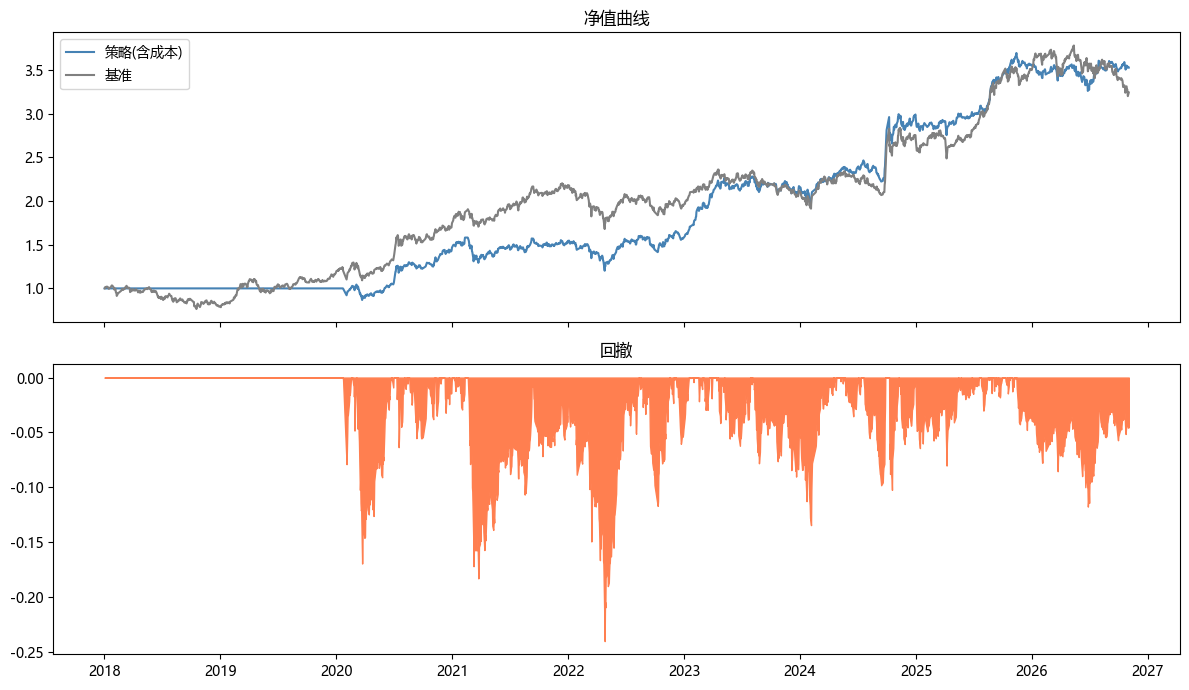

In [11]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(nav, label='策略(含成本)', color='steelblue')
ax[0].plot(bench_nav, label='基准', color='gray')
ax[0].set_title('净值曲线'); ax[0].legend()
dd = nav/nav.cummax()-1
ax[1].fill_between(dd.index, dd, 0, color='coral')
ax[1].set_title('回撤'); plt.tight_layout(); plt.show()

## 11. 模拟盘衔接

回测通过后，同一套信号可接入 `live_lab2` 的实时链路：
实时行情（`realtime_feed`）→ 信号 → 实时风控/熔断（`realtime_risk`）
→ 自适应执行（`adaptive_exec`）→ 报警与人工接管（`alert_handoff`），
通过可注入时钟与统一接口保证回测/实盘逻辑一致。

## 12. 结论与可改进方向

- 本策略在沪深 300 上用多因子 + LightGBM 滚动预测，样本外取得正 RankIC，
  含成本组合相对基准有超额收益；
- 可改进：扩充因子库与股票池（中证 500/全 A）、加入行业/风格约束优化、
  更精细的 TCA 与容量分析、模型集成与在线监控。